In [ ]:
from mast_toolkit_notebooks.plots import (
    plot_positive_metrics_by_category,
    to_percent_exc_nan
)
from mast_toolkit_notebooks.utils import (
    prepare_survey,
    DONT_KNOW,
)
import pandas as pd

survey = prepare_survey(verbose=False)
completed = survey.completedsurvey = prepare_survey()

responses = survey.responses
metadata = survey.metadata
analysis_df = survey.analysis_df
completed = survey.completed
rating_columns = survey.rating_columns
beliefs_columns = survey.beliefs_columns
action_columns = survey.action_columns
action_analysis_columns = survey.action_analysis_columns
self_assess_columns = survey.self_assess_columns
ai_outcome_columns = survey.ai_outcome_columns
recode_columns = survey.recode_columns

Loaded 178 responses from ../data/dataversity-2026/dataversity_survey_2iyUvU5Z4Pdi25fBvXwQsJ_responses.csv
Loaded metadata for 40 fields; 28 fields have choices.


## Original and recoded action–AI relationship

These 100% stacked bars compare original 1–5 AI-readiness ratings with the three-category recode. Leadership response `1` (“I don't do this”) and AI “don't know” responses are excluded; both panels use the same respondents.

In [ ]:
from scipy.stats import spearmanr
from textwrap import fill

x_column = "actions_endorse_1"
x_analysis_column = action_analysis_columns[x_column]
y_column = "ai_readiness"
recoded_column = f"{y_column}_recoded"

metadata_by_field = metadata.set_index("field_name")
action_question = metadata_by_field.loc[x_column, "question text"]
ai_question = metadata_by_field.loc[y_column, "question text"]
action_choice_labels = {
    int(choice["code"]): choice["value"]
    for choice in metadata_by_field.loc[x_column, "choices_parsed"]
}
ai_choice_labels = {
    int(choice["code"]): choice["value"]
    for choice in metadata_by_field.loc[y_column, "choices_parsed"]
}

# Exclude action rating 1 and AI "don't know", and keep the same respondents for both panels.
paired = completed[[x_analysis_column, y_column, recoded_column]].copy()
paired[[x_analysis_column, y_column]] = paired[[x_analysis_column, y_column]].replace(
    DONT_KNOW, float("nan")
)
paired = paired.dropna(subset=[x_analysis_column, y_column, recoded_column])

action_ratings = [2, 3, 4, 5]
ai_ratings = [1, 2, 3, 4, 5]
recoded_ratings = ["negative", "neutral", "positive"]
recoded_choice_labels = {
    "negative": "Negative (Strongly Disagree, Disagree)",
    "neutral": "Neutral (Neither Agree nor Disagree)",
    "positive": "Positive (Agree, Strongly Agree)",
}
recoded_scores = {label: score for score, label in enumerate(recoded_ratings, start=1)}
paired[f"{y_column}_recoded_score"] = paired[recoded_column].map(recoded_scores)

original_rho, original_p = spearmanr(paired[x_analysis_column], paired[y_column])
recoded_rho, recoded_p = spearmanr(
    paired[x_analysis_column], paired[f"{y_column}_recoded_score"]
)

original_counts = pd.crosstab(paired[x_analysis_column], paired[y_column]).reindex(
    index=action_ratings, columns=ai_ratings, fill_value=0
)
recoded_counts = pd.crosstab(paired[x_analysis_column], paired[recoded_column]).reindex(
    index=action_ratings, columns=recoded_ratings, fill_value=0
)
original_percent = to_percent_exc_nan(original_counts)
recoded_percent = to_percent_exc_nan(recoded_counts)

tick_labels = [
    f"{rating}: {fill(action_choice_labels[rating], width=28)}\n(n={int(original_counts.loc[rating].sum())})"
    for rating in action_ratings
]
original_colors = ["#b3586a", "#d99aa5", "#a9c2b5", "#80b89a", "#3d8c69"]
recoded_colors = ["#c66b78", "#a9c2b5", "#4f9b78"]

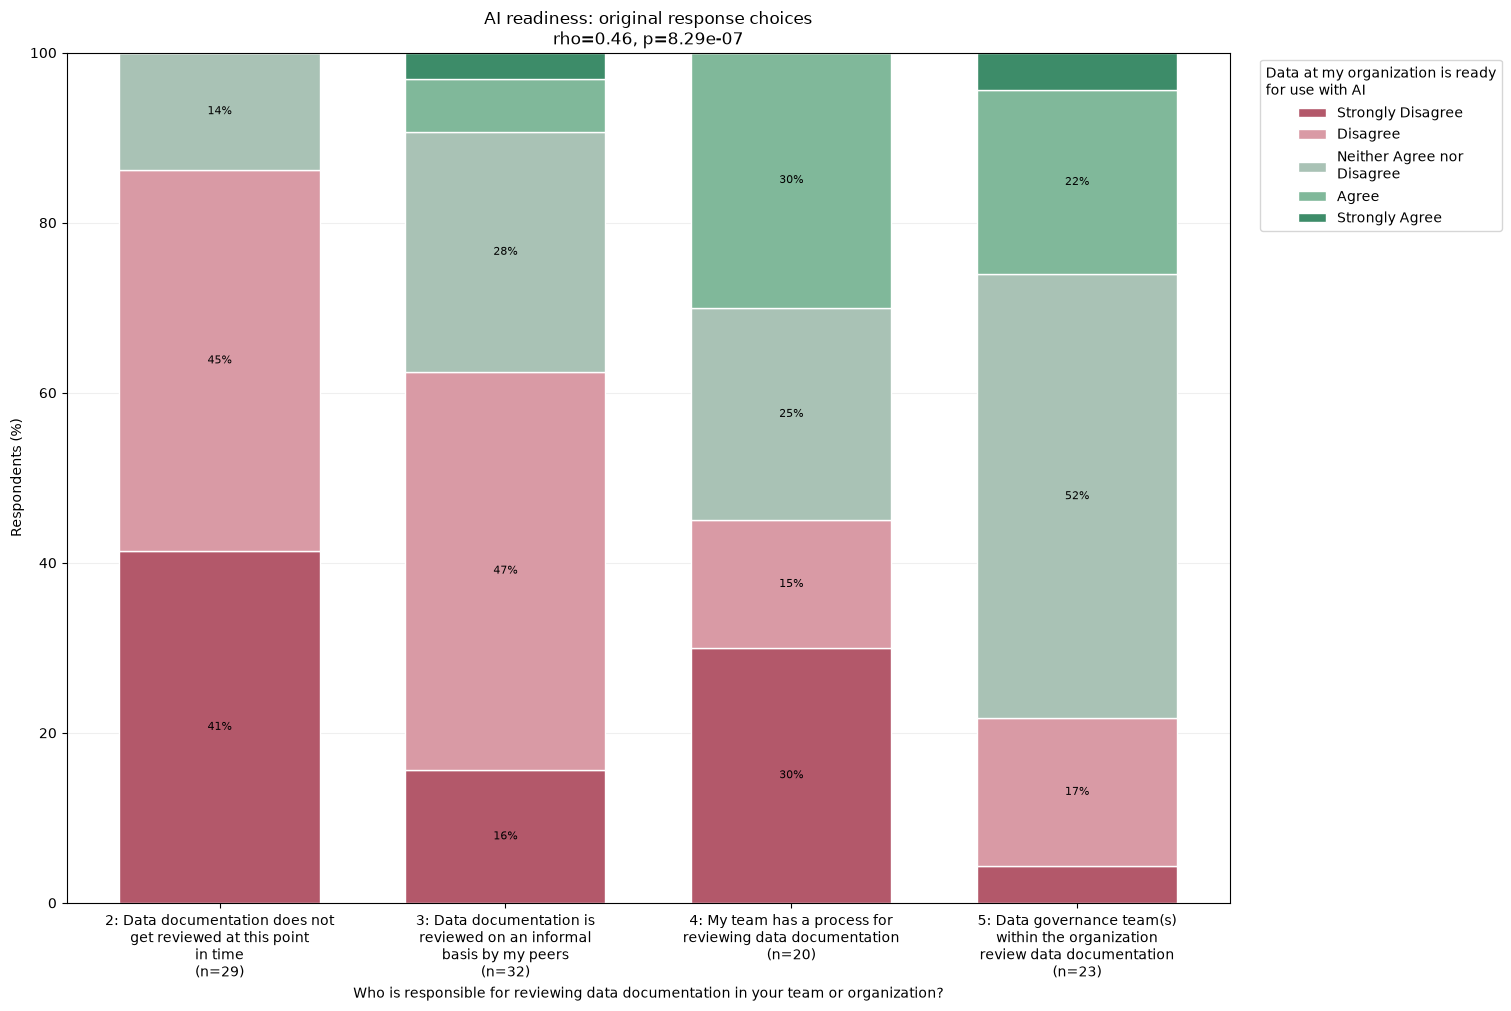

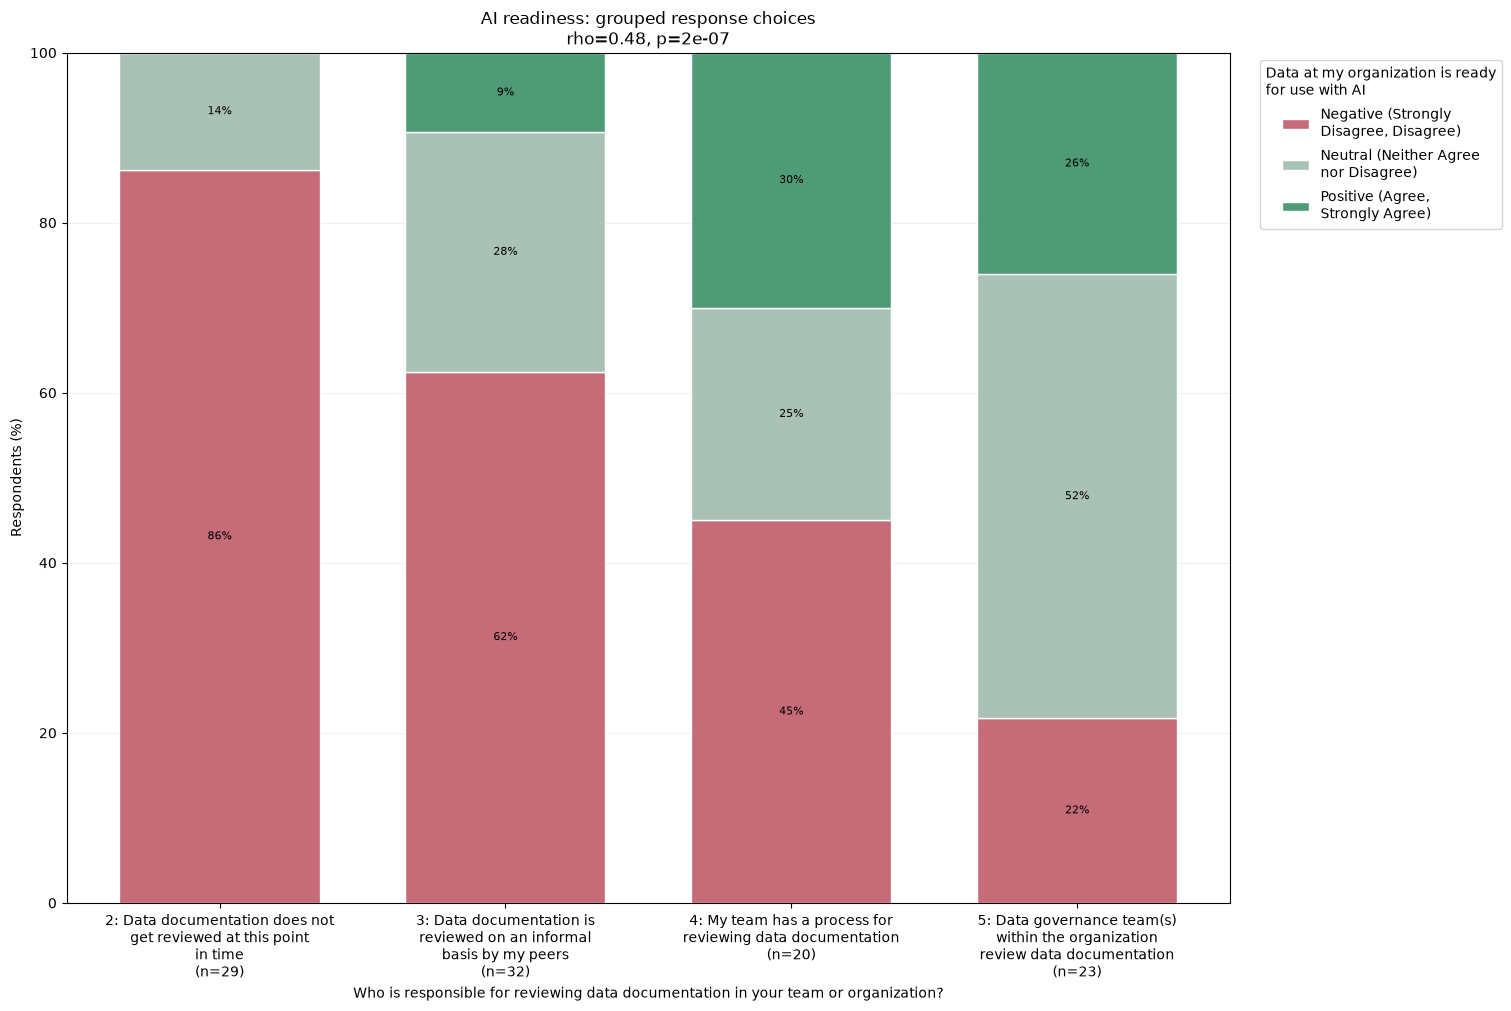

In [8]:
from textwrap import fill
import matplotlib.pyplot as plt


def plot_action_ai_stacked_bars(title, percentages, ratings, colors, labels, rho, p_value):
    figure, axis = plt.subplots(figsize=(15, 10), constrained_layout=True)
    bottom = [0.0] * len(action_ratings)
    for outcome_rating, color in zip(ratings, colors):
        heights = percentages.loc[action_ratings, outcome_rating].fillna(0).to_list()
        axis.bar(
            range(len(action_ratings)),
            heights,
            bottom=bottom,
            width=0.7,
            color=color,
            edgecolor="white",
            label=fill(labels[outcome_rating], width=24),
        )
        for position, height, start in zip(range(len(action_ratings)), heights, bottom):
            if height >= 8:
                axis.text(
                    position,
                    start + height / 2,
                    f"{height:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=8,
                )
        bottom = [start + height for start, height in zip(bottom, heights)]

    axis.set_title(f"{title}\nrho={rho:.2f}, p={p_value:.3g}")
    axis.set_xticks(range(len(action_ratings)), labels=tick_labels, rotation=0, ha="center")
    axis.set_xlabel(fill(action_question, width=90))
    axis.set_ylabel("Respondents (%)")
    axis.set_ylim(0, 100)
    axis.grid(axis="y", alpha=0.2)
    axis.set_axisbelow(True)
    axis.legend(title=fill(ai_question, width=35), bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.show()


plot_action_ai_stacked_bars(
    "AI readiness: original response choices",
    original_percent,
    ai_ratings,
    original_colors,
    ai_choice_labels,
    original_rho,
    original_p,
)
plot_action_ai_stacked_bars(
    "AI readiness: grouped response choices",
    recoded_percent,
    recoded_ratings,
    recoded_colors,
    recoded_choice_labels,
    recoded_rho,
    recoded_p,
)

## Positive AI outcomes by industry

Grouped bars show the percentage of valid AI-metric responses rated positive (`4` or `5`) within each industry. Industries with fewer than 5 completed responses are combined into `Other`; its rates are pooled from valid metric responses. Missing metric responses are excluded from each metric's denominator. X-axis labels show completed-response totals.

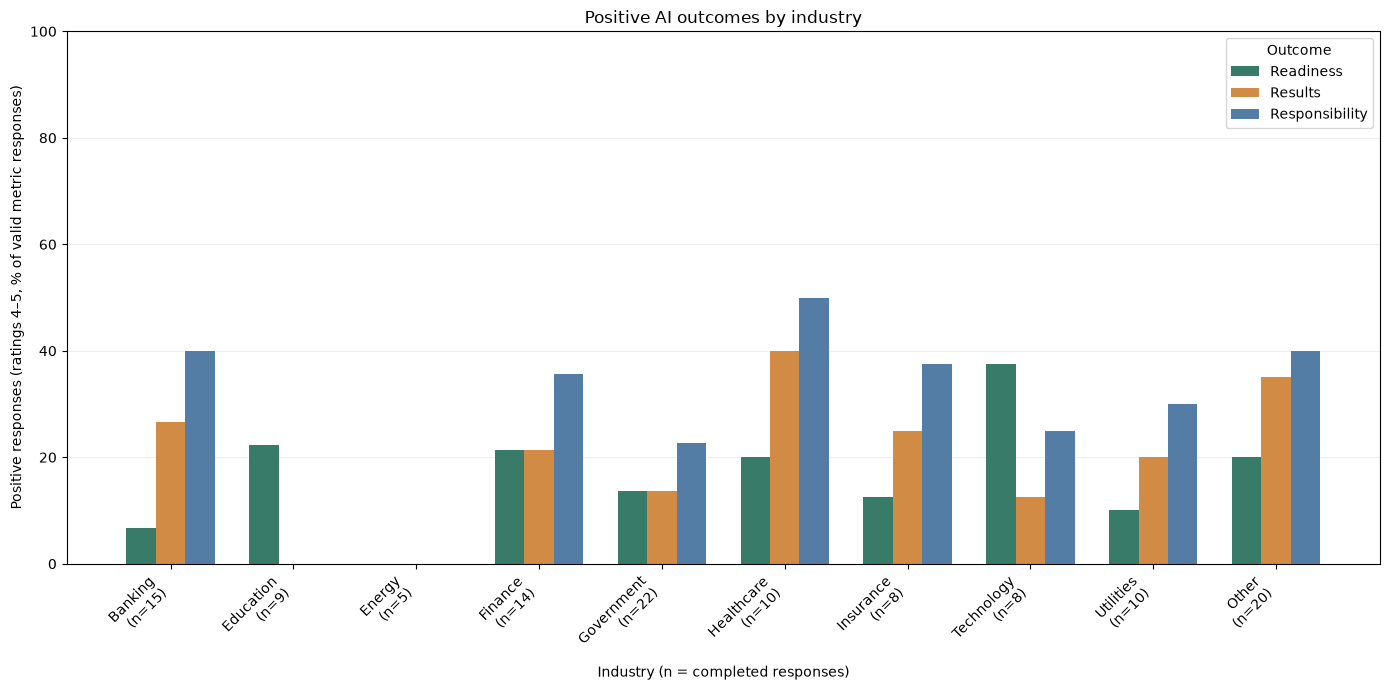

In [10]:
plot_positive_metrics_by_category(
    completed,
    "industry",
    survey.ai_outcome_columns,
    "Positive AI outcomes by industry",
)

## Positive self-assessment outcomes by industry

Grouped bars show the percentage of valid self-assessment responses rated positive (`4` or `5`) within each industry. As in the AI chart above, industries with fewer than 5 completed responses are combined into `Other`. Missing metric responses are excluded from each metric's denominator.

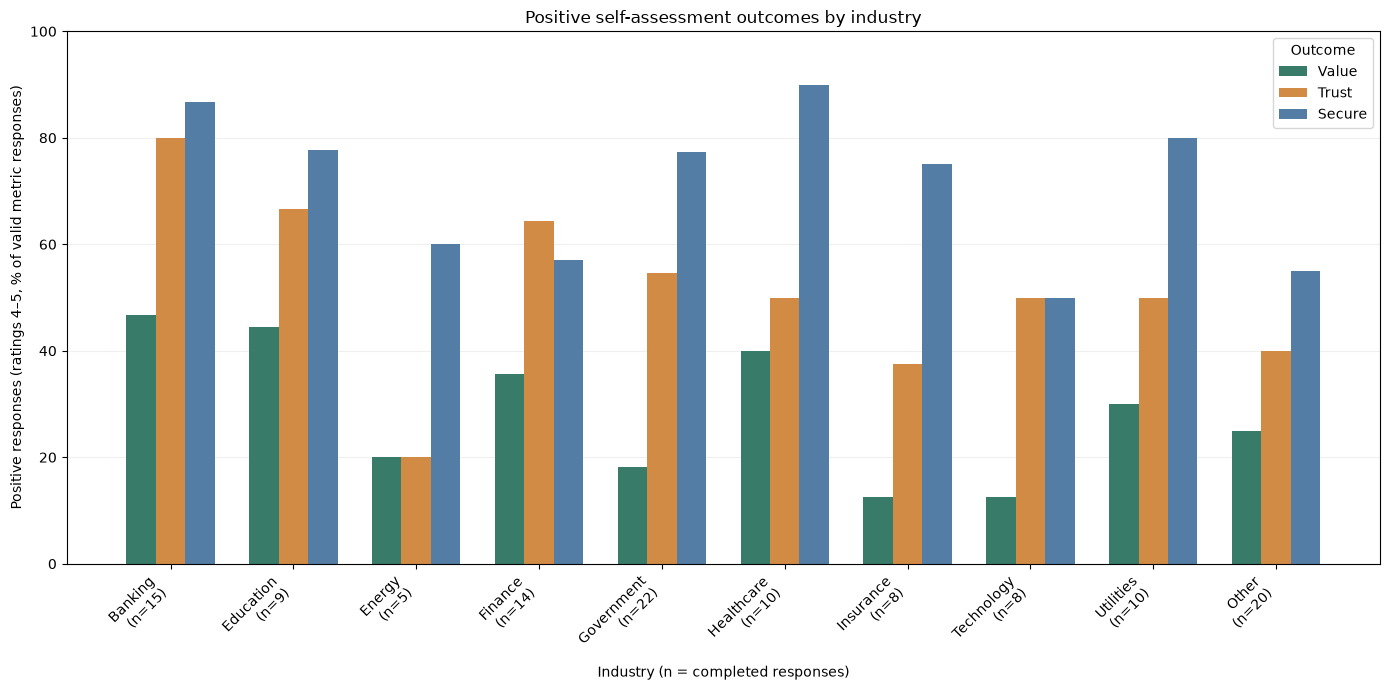

In [11]:
plot_positive_metrics_by_category(
    completed,
    "industry",
    survey.self_assess_columns,
    "Positive self-assessment outcomes by industry",
)

## Positive AI outcomes by job role

This chart uses the same grouped-bar calculation as the industry charts. Job roles with fewer than 5 completed responses are pooled into `Other`.

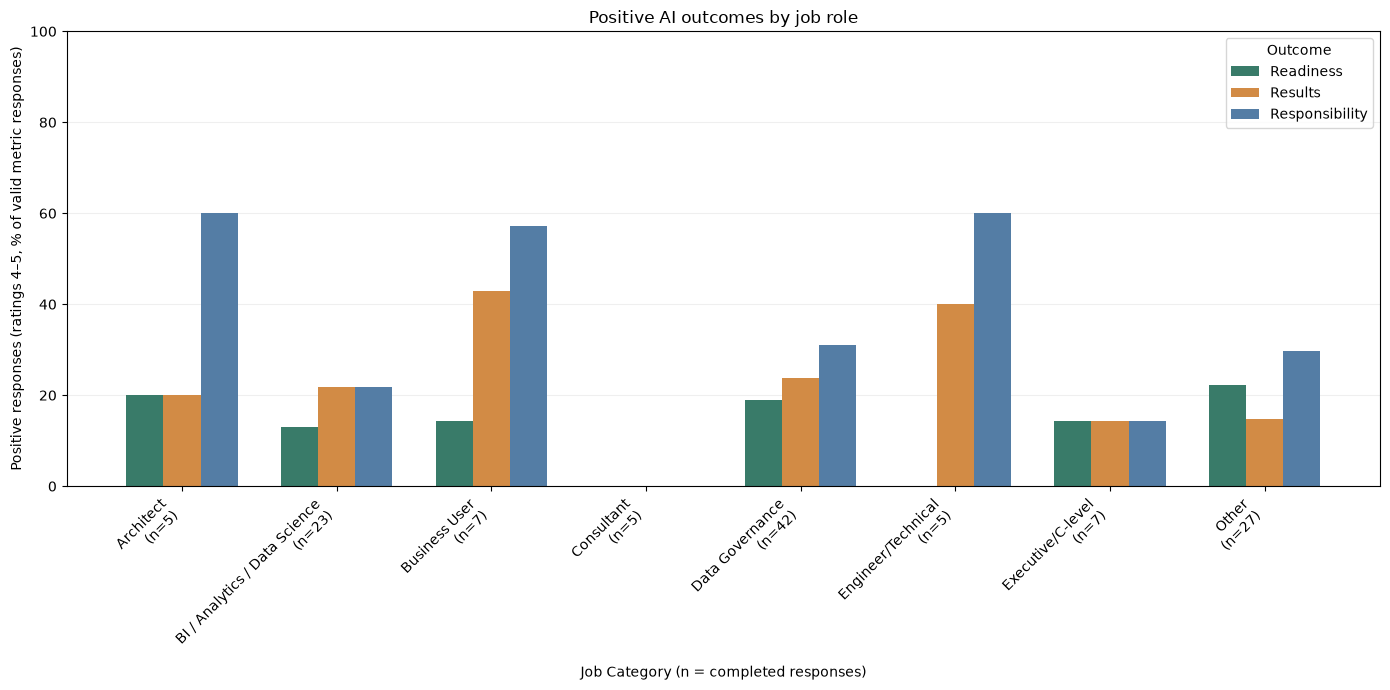

In [12]:
plot_positive_metrics_by_category(
    completed,
    "job_category",
    survey.ai_outcome_columns,
    "Positive AI outcomes by job role",
)

## Positive self-assessment outcomes by job role

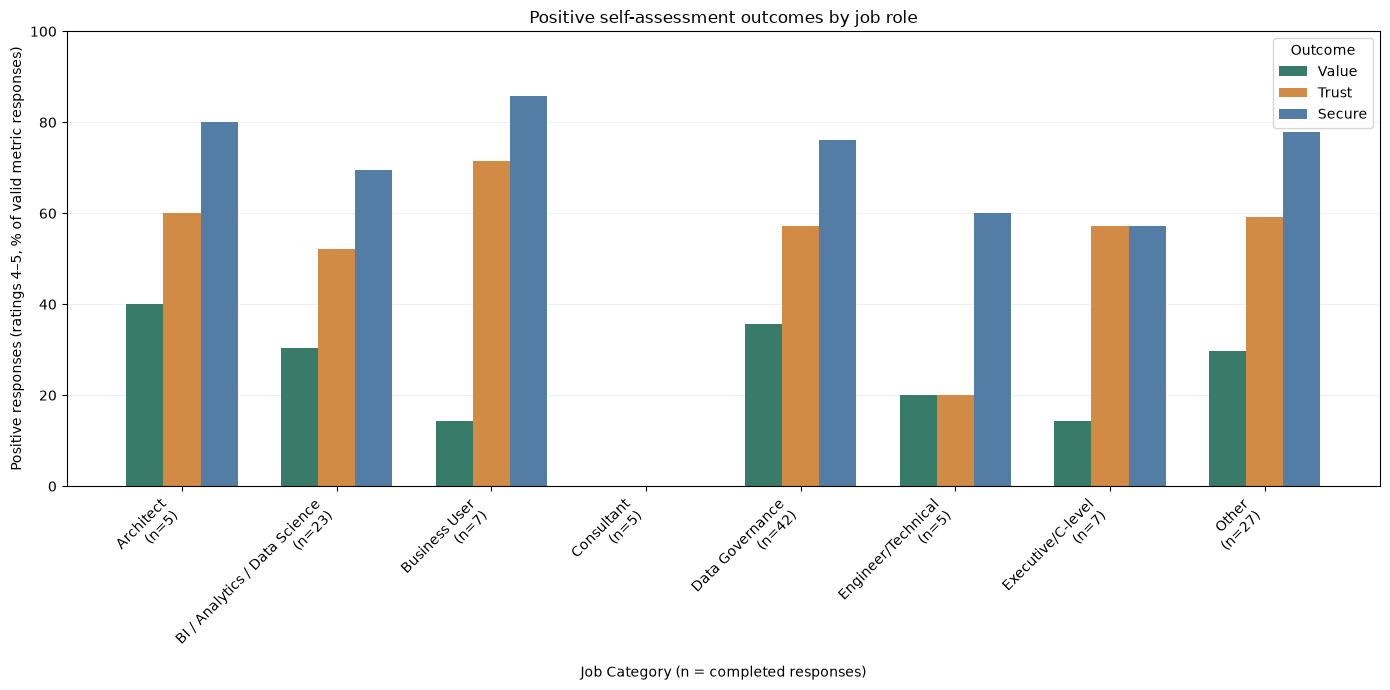

In [13]:
plot_positive_metrics_by_category(
    completed,
    "job_category",
    survey.self_assess_columns,
    "Positive self-assessment outcomes by job role",
)